#### Visulaization  Libararies
1) Matplotlib
2) seaborn
3) plotly
4) bokeh
5) altair
6) holoview
7) geo-pandas
8) pandas
9) folium
10) holoviews 
etc

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

#### Read the file

In [3]:
df = pd.read_csv('socialmedia.csv')
df.head()

,Student_ID,Age,Gender,Education_Level,Daily_Social_Media_Hours,Daily_AI_Tool_Usage_Hours,Sleep_Hours,Physical_Activity_Hours,Mental_Health_Score,Physical_Health_Score
0,STU_00001,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90
1,STU_00002,16,Non-binary,High School,5.21,3.89,7.81,2.48,76.13,89.94
2,STU_00003,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75
3,STU_00004,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38
4,STU_00005,20,Non-binary,College,6.52,1.64,5.23,1.14,67.74,88.04


In [4]:
df.duplicated().sum()

np.int64(0)

In [5]:
df.isnull().sum()

Student_ID                   0
Age                          0
Gender                       0
Education_Level              0
Daily_Social_Media_Hours     0
Daily_AI_Tool_Usage_Hours    0
Sleep_Hours                  0
Physical_Activity_Hours      0
Mental_Health_Score          0
Physical_Health_Score        0
dtype: int64

In [6]:
df.dtypes

Student_ID                    object
Age                            int64
Gender                        object
Education_Level               object
Daily_Social_Media_Hours     float64
Daily_AI_Tool_Usage_Hours    float64
Sleep_Hours                  float64
Physical_Activity_Hours      float64
Mental_Health_Score          float64
Physical_Health_Score        float64
dtype: object

In [8]:
df.columns = ['SID','Age','Gender','Education','SM_Hrs','AITools_hrs','Sleep_Hrs','PA_Hrs',
             'MH_Score','PH_Score']      
df.head()

,SID,Age,Gender,Education,SM_Hrs,AITools_hrs,Sleep_Hrs,PA_Hrs,MH_Score,PH_Score
0,STU_00001,19,Male,College,5.32,1.21,7.30,1.41,74.06,98.90
1,STU_00002,16,Non-binary,High School,5.21,3.89,7.81,2.48,76.13,89.94
2,STU_00003,25,Male,University,3.61,2.65,6.34,0.06,65.01,76.75
3,STU_00004,23,Male,University,2.93,1.43,6.12,1.37,74.67,87.38
4,STU_00005,20,Non-binary,College,6.52,1.64,5.23,1.14,67.74,88.04


#### Graph Application

1) Bar Chart -  Used to compare continuous values for different categories.

2) Line Chart - Used to represent trend line (datetime)

3) Pie Chart -  Used to represent percentage

4) Histogram - Used to represent frequency distrbiution

5) Scatter Chart - Used to represent correlation between 2 numeric varaibles

6) Boxplot - Used to represent outliers, quartile distribution

#### Q1) Create a Bar chart for Education wise avg SM_hrs

In [9]:
q1 = df.groupby('Education')['SM_Hrs'].mean()
q1

Education
College        4.488485
High School    4.571892
University     4.557221
Name: SM_Hrs, dtype: float64

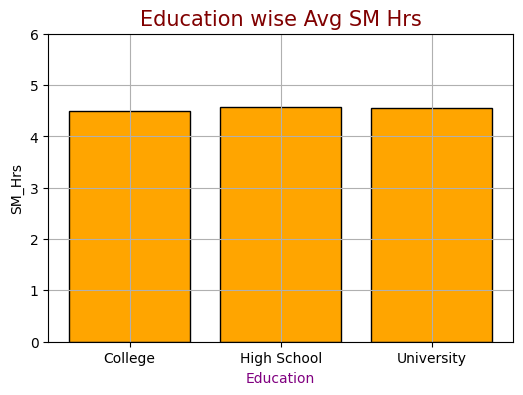

In [25]:
# plt.bar(x,y)
plt.figure(figsize=(6,4))   # width=8, height = 4
plt.bar(q1.index, q1.values,color='orange',edgecolor='black')   
plt.title('Education wise Avg SM Hrs',color='maroon',size=15)
plt.xlabel('Education',color='purple')   
plt.ylabel('SM_Hrs')
plt.ylim(0,6)   # ylimit
plt.grid()
plt.savefig('bar_chart.png')
plt.show()

#### Q2) Represent gender wise avg MH_Score and Avg PH_Score on a bar chart

In [26]:
q2 = df.groupby('Gender')[['MH_Score','PH_Score']].mean()
q2

,MH_Score,PH_Score
Gender,,
Female,72.535110,87.936658
Male,72.481782,88.130382
Non-binary,72.124761,87.683010


In [29]:
q2.columns

Index(['MH_Score', 'PH_Score'], dtype='object')

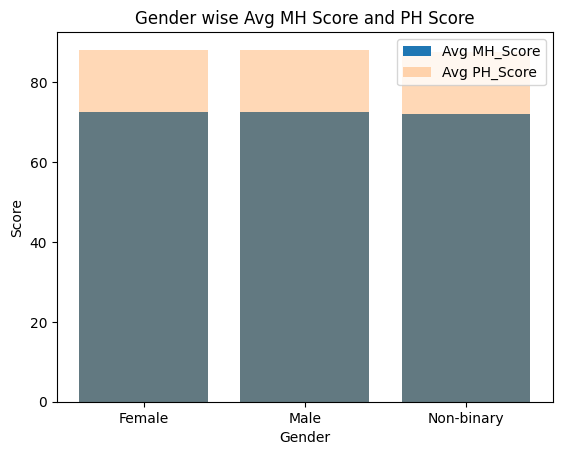

In [36]:
plt.bar(q2.index,q2['MH_Score'],label='Avg MH_Score')
plt.bar(q2.index,q2['PH_Score'],label='Avg PH_Score',alpha=0.3)   # alpha = used to set transparency
plt.title('Gender wise Avg MH Score and PH Score')     
plt.xlabel('Gender')
plt.ylabel('Score')
plt.legend()    # used to display label
plt.show()

#### Q3)  Represent SM_Hrs vs PA_Hrs on a scatter chart for College students

In [38]:
df.columns

Index(['SID', 'Age', 'Gender', 'Education', 'SM_Hrs', 'AITools_hrs',
       'Sleep_Hrs', 'PA_Hrs', 'MH_Score', 'PH_Score'],
      dtype='object')

In [40]:
col_df = df[df['Education']=='College']  
col_df.shape   

(4890, 10)

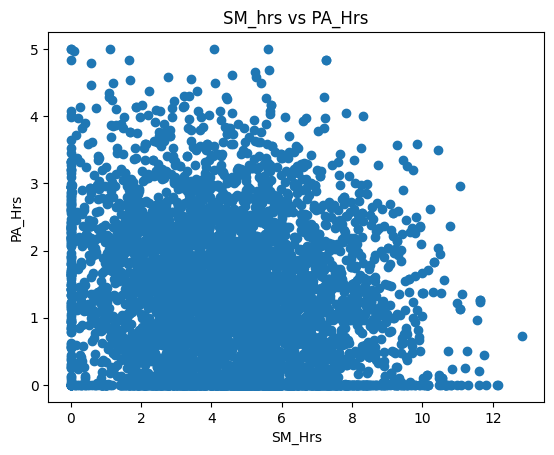

In [42]:
# plt.scatter(x,y)
plt.scatter(col_df['SM_Hrs'],col_df['PA_Hrs'])
plt.title('SM_hrs vs PA_Hrs')  
plt.xlabel('SM_Hrs')
plt.ylabel('PA_Hrs')
plt.show()

#### Q4) Represent AI_Tools_Hrs for Males on a histogram

In [46]:
# df.columns

In [44]:
q3 = df[df['Gender']=='Male']
q3.shape

(7744, 10)

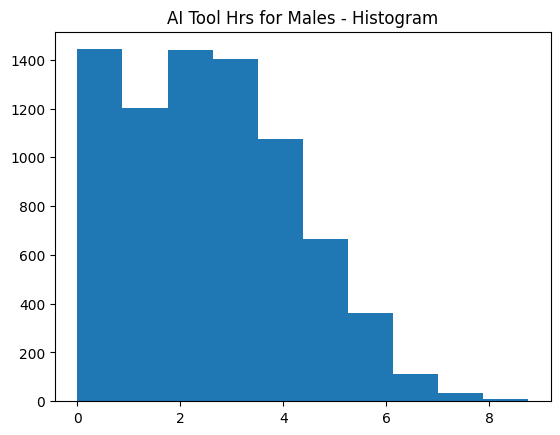

In [45]:
# plt.hist(x)
plt.hist(q3['AITools_hrs'])
plt.title('AI Tool Hrs for Males - Histogram')
plt.show()

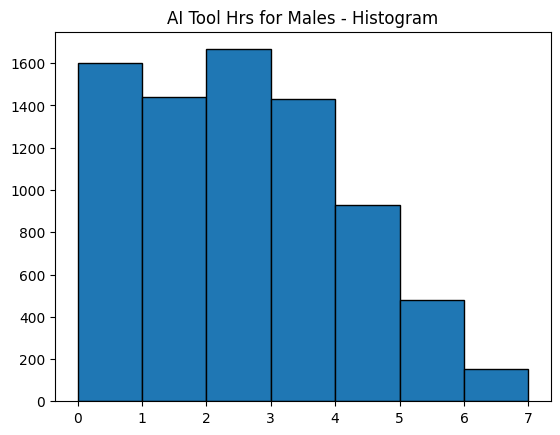

In [50]:
plt.hist(q3['AITools_hrs'],bins=list(range(0,8)),edgecolor='black')  # bins = [0,1,2,3,4,5,6,7]
plt.title('AI Tool Hrs for Males - Histogram')  
plt.show()

# bins decides the number of groups in which we wish to divide the numerical data

#### Q5) Compare SM_Hrs for College and High School students on a histogram

In [51]:
q5a = df[df['Education']=='College']
q5b = df[df['Education']=='High School']

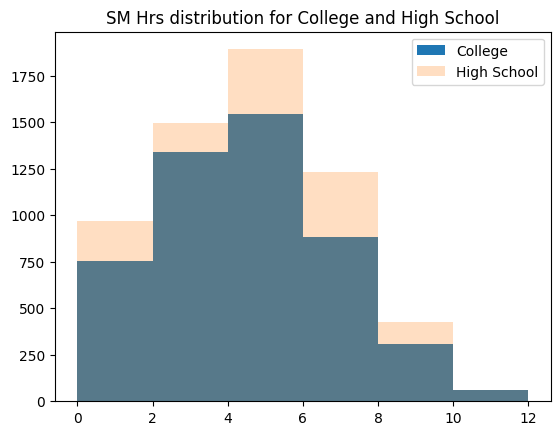

In [54]:
plt.hist(q5a['SM_Hrs'],label='College',bins=list(range(0,13,2)))
plt.hist(q5b['SM_Hrs'],label='High School',bins=list(range(0,13,2)),alpha = 0.25)
plt.title('SM Hrs distribution for College and High School')   
plt.legend()
plt.show()

#### Q6) Represent %age distribution for Education wise sum of SM_Hrs

In [57]:
q6 = df.groupby('Education')['SM_Hrs'].sum()
q6

Education
College        21948.69
High School    27810.82
University     22909.15
Name: SM_Hrs, dtype: float64

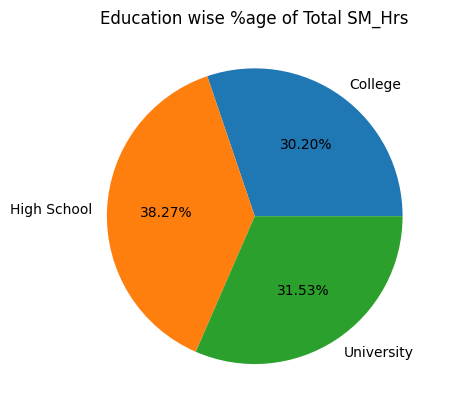

In [62]:
# plt.pie(x,labels)
plt.pie(q6.values, labels=q6.index, autopct='%.2f%%')   # autopct = auto percenatge
plt.title('Education wise %age of Total SM_Hrs')   
plt.show()

#### Q7) Find gender and Education wise sleep Hrs. Represent its %age distrbution on a pie chart

In [63]:
q7 = df.groupby(['Gender','Education'])['Sleep_Hrs'].sum()  
q7

Gender      Education  
Female      College        15414.27
            High School    19100.86
            University     15443.45
Male        College        15371.28
            High School    19250.22
            University     16080.23
Non-binary  College         1389.96
            High School     1424.12
            University      1251.55
Name: Sleep_Hrs, dtype: float64

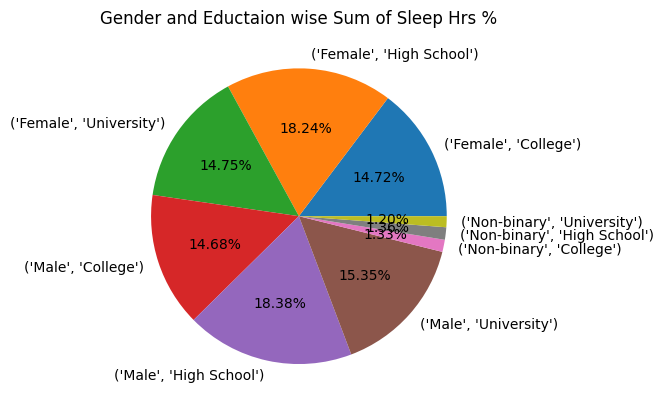

In [64]:
plt.pie(q7.values, labels=q7.index,autopct='%.2f%%')
plt.title('Gender and Eductaion wise Sum of Sleep Hrs %')
plt.show()    